In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW = Path("../data/raw")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.2f}".format

In [2]:
events = pd.read_csv(RAW / "events.csv")
events["time"] = pd.to_datetime(events["timestamp"], unit="ms")
print(events.shape)
display(events.head())
display(events.dtypes.to_frame("dtype").join(events.isna().mean().rename("null_share")))

(2756101, 6)


,timestamp,visitorid,event,itemid,transactionid,time
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


,dtype,null_share
timestamp,int64,0.00
visitorid,int64,0.00
event,str,0.00
itemid,int64,0.00
transactionid,float64,0.99
time,datetime64[us],0.00


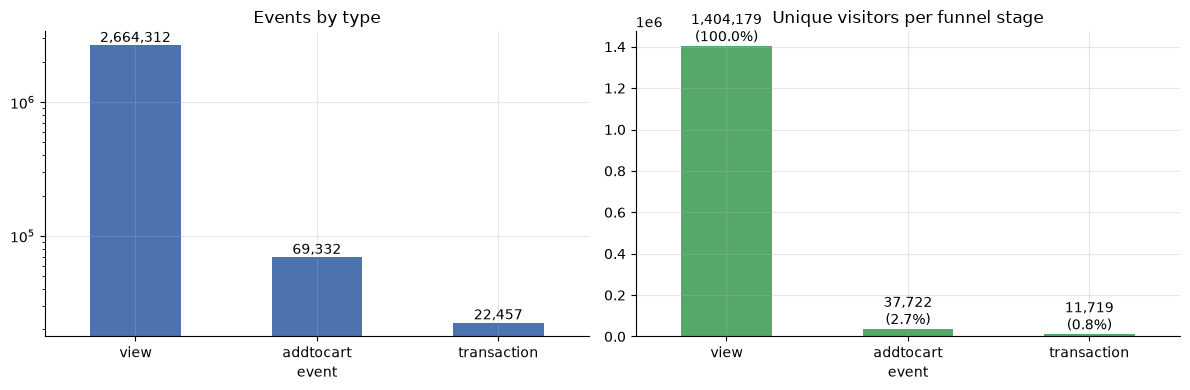

In [3]:
cnt = events["event"].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cnt.plot.bar(ax=ax[0], color="#4c72b0", rot=0, title="Events by type")
ax[0].set_yscale("log")
for i, v in enumerate(cnt):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")

visitors = events.groupby("event")["visitorid"].nunique().reindex(["view", "addtocart", "transaction"])
visitors.plot.bar(ax=ax[1], color="#55a868", rot=0, title="Unique visitors per funnel stage")
for i, v in enumerate(visitors):
    ax[1].text(i, v, f"{v:,}\n({v / visitors.iloc[0]:.1%})", ha="center", va="bottom")
plt.tight_layout()

Period: 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000


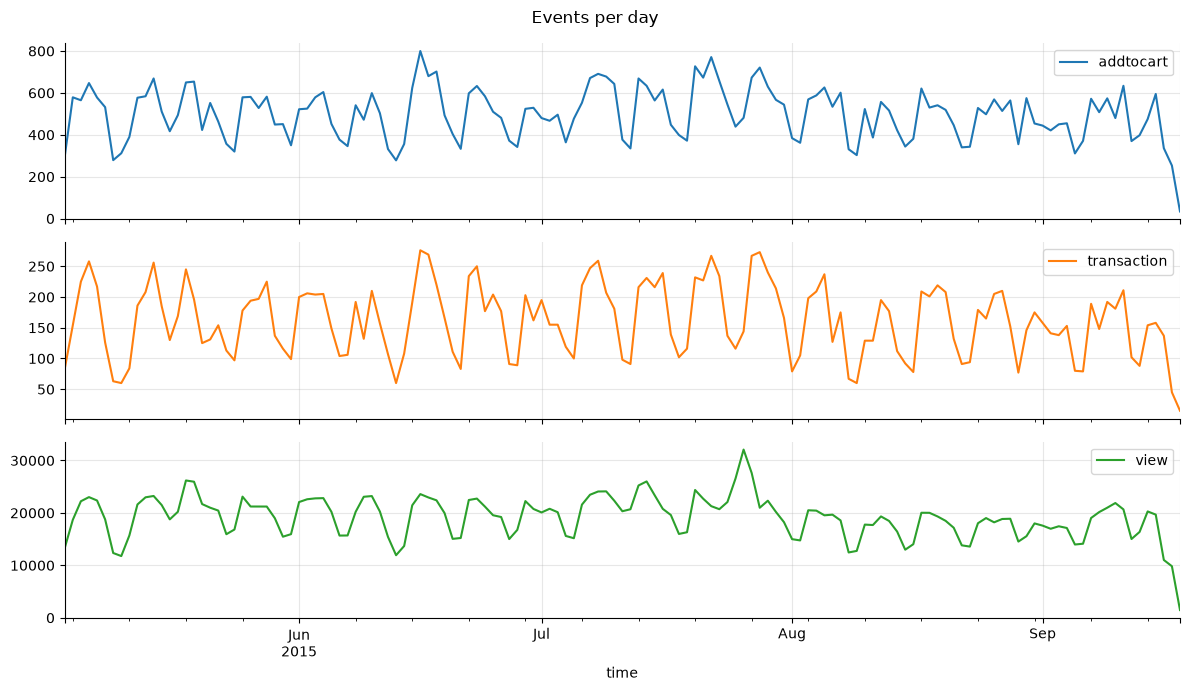

In [4]:
print("Period:", events["time"].min(), "->", events["time"].max())
daily = events.set_index("time").groupby("event").resample("D").size().unstack(0).fillna(0)
daily.plot(subplots=True, figsize=(12, 7), sharex=True, title="Events per day")
plt.tight_layout()

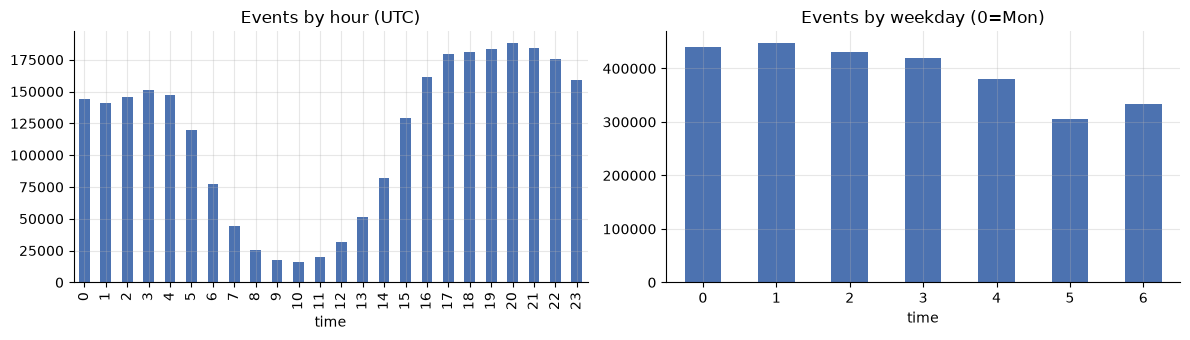

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
events.groupby(events["time"].dt.hour).size().plot.bar(ax=ax[0], title="Events by hour (UTC)", color="#4c72b0")
events.groupby(events["time"].dt.day_of_week).size().plot.bar(ax=ax[1], title="Events by weekday (0=Mon)", color="#4c72b0", rot=0)
plt.tight_layout()

Visitors: 1,407,580   Items: 235,061
Visitors with 1 event: 71.2%
Median events per visitor: 1.0  p99: 13.0


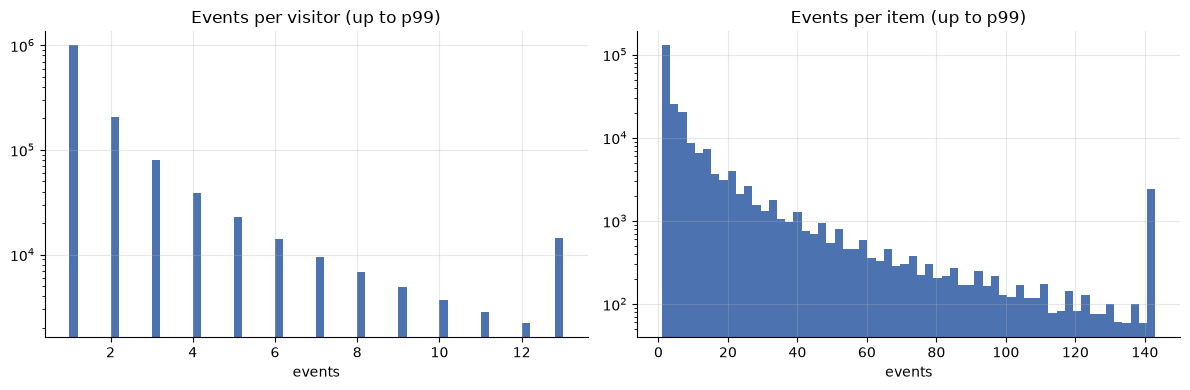

In [6]:
per_user = events.groupby("visitorid").size()
per_item = events.groupby("itemid").size()
print(f"Visitors: {len(per_user):,}   Items: {len(per_item):,}")
print("Visitors with 1 event:", f"{(per_user == 1).mean():.1%}")
print("Median events per visitor:", per_user.median(), " p99:", per_user.quantile(.99))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, s, name in [(ax[0], per_user, "visitor"), (ax[1], per_item, "item")]:
    a.hist(s.clip(upper=s.quantile(.99)), bins=60, color="#4c72b0")
    a.set_yscale("log"); a.set_title(f"Events per {name} (up to p99)"); a.set_xlabel("events")
plt.tight_layout()

Text(0, 0.5, 'share of events')

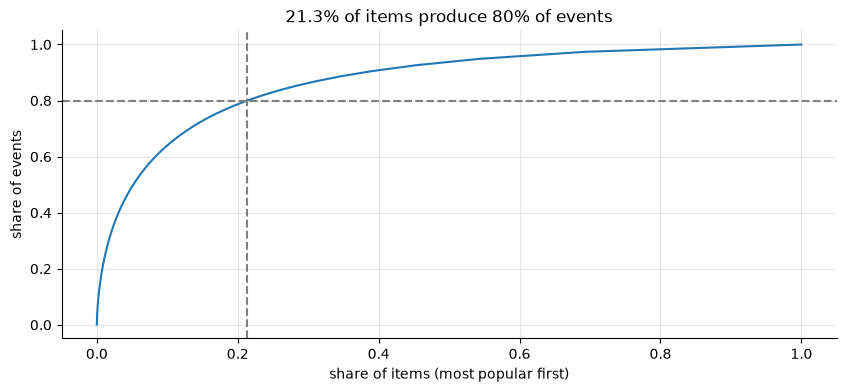

In [7]:
share = per_item.sort_values(ascending=False).cumsum() / per_item.sum()
x = np.arange(1, len(share) + 1) / len(share)
plt.plot(x, share.values)
n80 = (share < .8).sum() / len(share)
plt.axhline(.8, ls="--", c="gray"); plt.axvline(n80, ls="--", c="gray")
plt.title(f"{n80:.1%} of items produce 80% of events")
plt.xlabel("share of items (most popular first)"); plt.ylabel("share of events")

In [8]:
inter = events.groupby(["visitorid", "itemid"]).size()
n_u, n_i = events["visitorid"].nunique(), events["itemid"].nunique()
print(f"Unique user-item pairs: {len(inter):,}")
print(f"Matrix density: {len(inter) / (n_u * n_i):.6%}")

rows = []
for k in [1, 2, 3, 5, 10]:
    u = per_user[per_user >= k].index
    rows.append((k, len(u), events["visitorid"].isin(u).mean()))
pd.DataFrame(rows, columns=["min_events", "users_left", "events_share_left"])

Unique user-item pairs: 2,145,179
Matrix density: 0.000648%


,min_events,users_left,events_share_left
0,1,1407580,1.00
1,2,406020,0.64
2,3,200028,0.49
3,5,81620,0.34
4,10,23241,0.21


Visitors with >=2 items: 20.5%


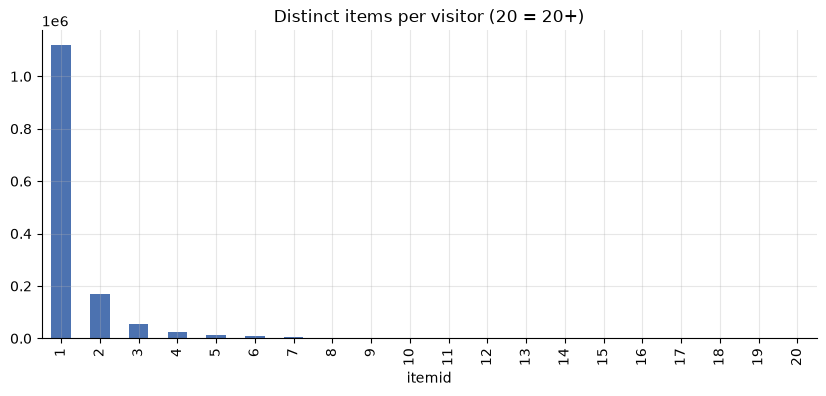

In [9]:
items_per_user = events.groupby("visitorid")["itemid"].nunique()
items_per_user.clip(upper=20).value_counts().sort_index().plot.bar(color="#4c72b0", title="Distinct items per visitor (20 = 20+)")
print(f"Visitors with >=2 items: {(items_per_user >= 2).mean():.1%}")

Transactions: 17672
Buyers: 11719   Items bought: 12025
Mean basket size: 1.27
View->transaction conversion, top-1000 viewed items: 1.13%


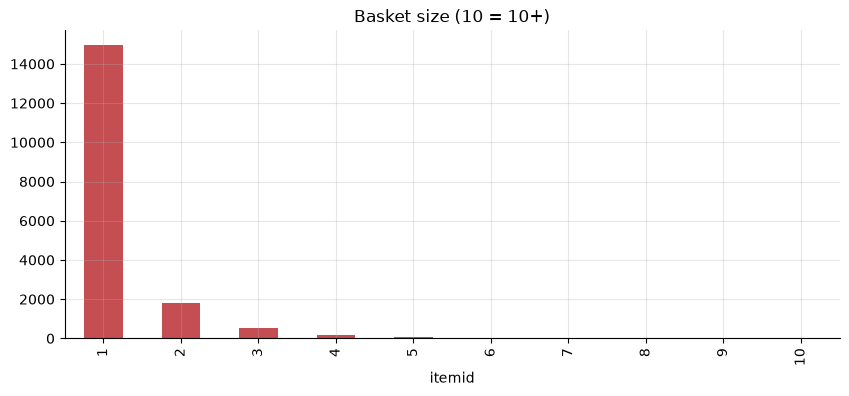

In [10]:
tx = events[events["event"] == "transaction"]
print("Transactions:", tx["transactionid"].nunique())
print("Buyers:", tx["visitorid"].nunique(), "  Items bought:", tx["itemid"].nunique())
basket = tx.groupby("transactionid")["itemid"].count()
print("Mean basket size:", round(basket.mean(), 2))
basket.clip(upper=10).value_counts().sort_index().plot.bar(title="Basket size (10 = 10+)", color="#c44e52")

conv = events.pivot_table(index="itemid", columns="event", values="visitorid", aggfunc="count", fill_value=0)
top = conv.sort_values("view", ascending=False).head(1000)
print("View->transaction conversion, top-1000 viewed items:", f"{top['transaction'].sum() / top['view'].sum():.2%}")

View->buy pairs: 18,738, bought within 1h: 77.7%


<Axes: title={'center': 'Hours from first view to purchase (capped at 14 days)'}, ylabel='Frequency'>

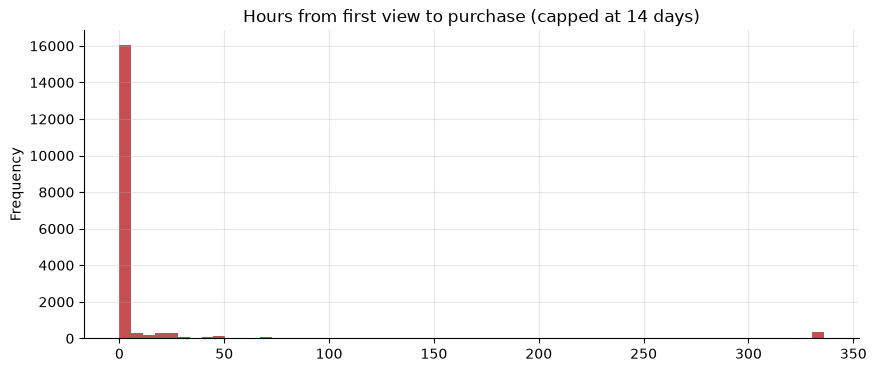

In [11]:
first_view = events[events.event == "view"].groupby(["visitorid", "itemid"])["time"].min()
first_buy = tx.groupby(["visitorid", "itemid"])["time"].min()
lag = (first_buy - first_view).dropna().dt.total_seconds() / 3600
lag = lag[lag >= 0]
print(f"View->buy pairs: {len(lag):,}, bought within 1h: {(lag <= 1).mean():.1%}")
lag.clip(upper=24 * 14).plot.hist(bins=60, color="#c44e52", title="Hours from first view to purchase (capped at 14 days)")

(1669, 2)  roots: 25


parentid
250     31
362     22
1009    22
351     19
1259    18
dtype: int64

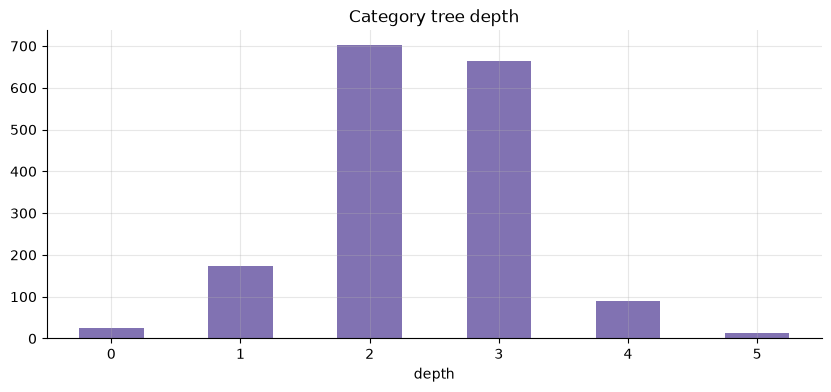

In [12]:
cat = pd.read_csv(RAW / "category_tree.csv")
print(cat.shape, " roots:", cat["parentid"].isna().sum())

parent = dict(zip(cat["categoryid"], cat["parentid"]))
def depth(c):
    d = 0
    while pd.notna(parent.get(c)):
        c = parent[c]; d += 1
        if d > 50: break
    return d
cat["depth"] = cat["categoryid"].map(depth)
cat["depth"].value_counts().sort_index().plot.bar(rot=0, title="Category tree depth", color="#8172b2")
children = cat.groupby("parentid").size()
children.sort_values(ascending=False).head(5).rename(lambda x: int(x))

In [13]:
props = pd.concat([pd.read_csv(RAW / f"item_properties_part{i}.csv") for i in (1, 2)], ignore_index=True)
props["time"] = pd.to_datetime(props["timestamp"], unit="ms")
print(props.shape, " items:", props["itemid"].nunique(), " properties:", props["property"].nunique())
props.head()

(20275902, 5)  items: 417053  properties: 1104


,timestamp,itemid,property,value,time
0,1435460400000,460429,categoryid,1338,2015-06-28 03:00:00
1,1441508400000,206783,888,1116713 960601 n277.200,2015-09-06 03:00:00
2,1439089200000,395014,400,n552.000 639502 n720.000 424566,2015-08-09 03:00:00
3,1431226800000,59481,790,n15360.000,2015-05-10 03:00:00
4,1431831600000,156781,917,828513,2015-05-17 03:00:00


property
888           3000398
790           1790516
available     1503639
categoryid     788214
6              631471
283            597419
776            574220
678            481966
364            476486
202            448938
839            417239
917            417227
159            417053
764            417053
112            417053
Name: count, dtype: int64

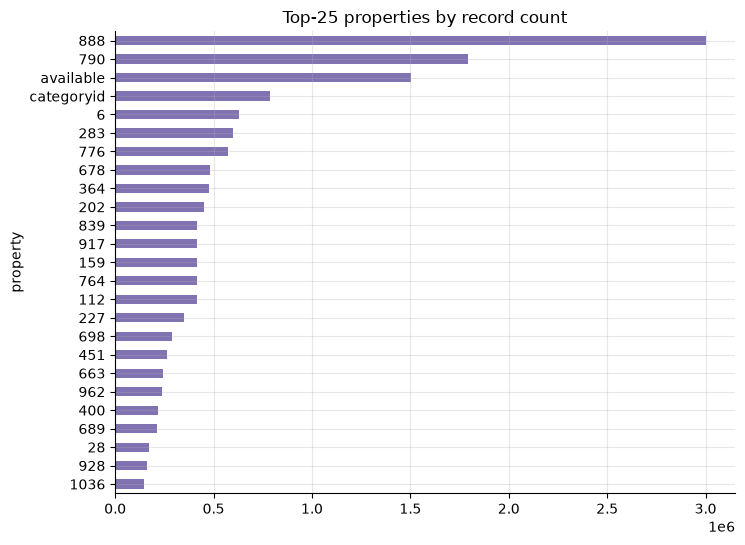

In [14]:
pc = props["property"].value_counts()
display(pc.head(15))
pc.head(25).plot.barh(figsize=(8, 6), title="Top-25 properties by record count", color="#8172b2").invert_yaxis()

Event items with categoryid: 78.8%
Event items with any property: 78.8%


<Axes: title={'center': 'Items in top-30 categories'}, xlabel='value'>

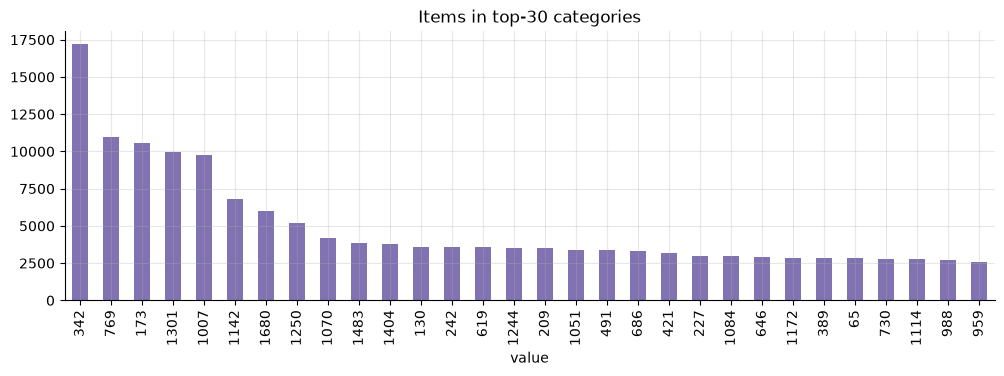

In [15]:
cat_prop = props[props["property"] == "categoryid"]
items_ev = set(events["itemid"].unique())
print(f"Event items with categoryid: {len(items_ev & set(cat_prop['itemid'])) / len(items_ev):.1%}")
print(f"Event items with any property: {len(items_ev & set(props['itemid'])) / len(items_ev):.1%}")

latest_cat = cat_prop.sort_values("time").groupby("itemid")["value"].last().astype(int)
items_per_cat = latest_cat.value_counts()
items_per_cat.head(30).plot.bar(figsize=(12, 3.5), title="Items in top-30 categories", color="#8172b2")

In [ ]:
av = props[props["property"] == "available"]
print("Share of available=1 records:", f"{(av['value'] == '1').mean():.1%}")
chg = props.groupby(["itemid", "property"]).size()
print("Item-property pairs changed more than once:", f"{(chg > 1).mean():.1%}")

Share of available=1 records: 42.6%
